In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
dataset_path = Path("../dataset/processed/creditcard_clean.csv")

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (283726, 31)


In [3]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (283726, 30)
Target: (283726,)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (226980, 30)
Testing: (56746, 30)


In [5]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [6]:
best_model = search.best_estimator_

print("Best tuned model retrieved!")

NameError: name 'search' is not defined

In [7]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), ["Time", "Amount"])
    ],
    remainder="passthrough"
)

best_model = Pipeline([
    ("preprocessing", preprocessor),
    ("smote", SMOTE(
        sampling_strategy=0.1,
        random_state=42
    )),
    ("model", RandomForestClassifier(
        n_estimators=50,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

best_model.fit(X_train, y_train)

print("Tuned Random Forest training completed!")

Tuned Random Forest training completed!


In [8]:
y_pred_tuned = best_model.predict(X_test)

y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [9]:
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    roc_auc_score
)

print(classification_report(y_test, y_pred_tuned))

print("PR-AUC:",
      average_precision_score(y_test, y_prob_tuned))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_tuned))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.84      0.80      0.82        95

    accuracy                           1.00     56746
   macro avg       0.92      0.90      0.91     56746
weighted avg       1.00      1.00      1.00     56746

PR-AUC: 0.8199291141918236
ROC-AUC: 0.9772828834721178


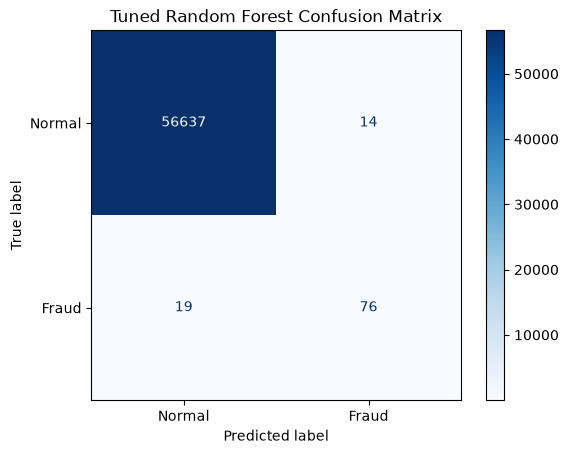

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["Normal", "Fraud"],
    cmap="Blues"
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.show()

In [11]:
joblib.dump(
    best_model,
    "../models/best_fraud_detection_pipeline.pkl"
)

print("Final pipeline saved successfully!")

Final pipeline saved successfully!


In [12]:
import joblib

loaded_model = joblib.load(
    "../models/best_fraud_detection_pipeline.pkl"
)

print("Model loaded successfully!")

sample_predictions = loaded_model.predict(X_test.head(5))

print("Predictions:", sample_predictions)

Model loaded successfully!
Predictions: [0 0 0 0 0]


In [13]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SMOTE Random Forest",
        "Tuned Random Forest"
    ],
    "PR-AUC": [
        0.6719,
        0.4961,
        0.7991,
        0.8178,
        0.8199
    ],
    "ROC-AUC": [
        0.9658,
        0.9074,
        0.9752,
        0.9752,
        0.9773
    ]
})

model_comparison

,Model,PR-AUC,ROC-AUC
0,Logistic Regression,0.6719,0.9658
1,Decision Tree,0.4961,0.9074
2,Random Forest,0.7991,0.9752
3,SMOTE Random Forest,0.8178,0.9752
4,Tuned Random Forest,0.8199,0.9773


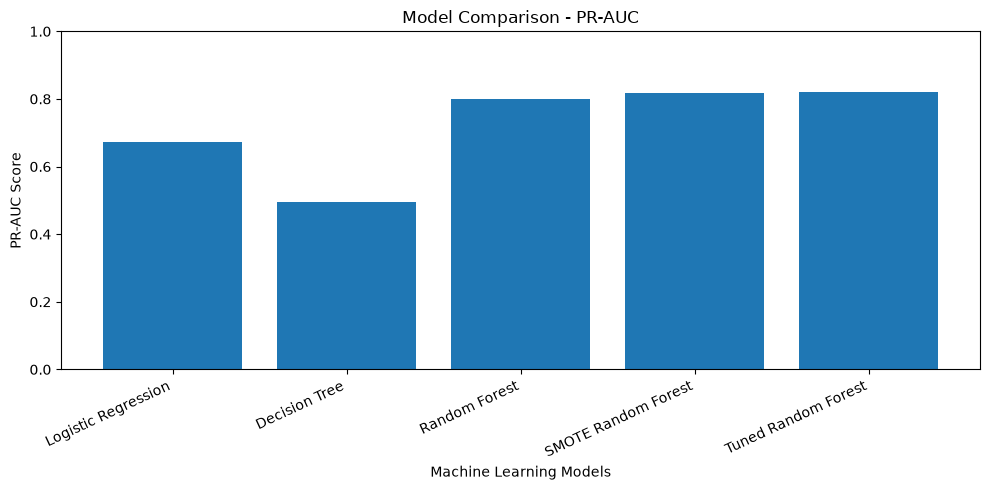

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["PR-AUC"]
)

plt.title("Model Comparison - PR-AUC")
plt.xlabel("Machine Learning Models")
plt.ylabel("PR-AUC Score")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()